# Lotka–Volterra Predator–Prey Dynamics

This project implements the Lotka–Volterra model to simulate interactions between predator and prey populations using Python.

The model represents a nonlinear dynamical system in which prey populations grow in the absence of predators, while predator populations depend on prey availability for survival and reproduction.

Using numerical integration, the project investigates population oscillations, equilibrium behavior, parameter sensitivity, and numerical stability. The analysis compares Euler's method with the midpoint method and extends the original model to incorporate logistic prey growth.

The project demonstrates how computational methods can be used to investigate biological population dynamics and evaluate the accuracy of numerical simulations.

---
### Mathematical Model

The Lotka–Volterra model describes the interaction between two populations:

- **Prey ($x$):** A population that reproduces naturally but experiences mortality through predation.
- **Predators ($y$):** A population that depends on prey consumption for reproduction and experiences natural mortality.

The system is represented by two coupled differential equations:

$$\frac{dx}{dt} = \underbrace{\alpha x}_{\text{prey grow}} - \underbrace{\beta x y}_{\text{prey eaten}}
\qquad\qquad
\frac{dy}{dt} = \underbrace{\delta x y}_{\text{eating pays}} - \underbrace{\gamma y}_{\text{predators die}}$$

The parameters represent:

- $(\alpha)$: Intrinsic prey growth rate
- $(\beta)$: Predation interaction coefficient
- $(\gamma)$: Predator mortality rate
- $(\delta)$: Predator growth coefficient associated with prey consumption

The nonzero equilibrium occurs when:

$$
x^*=\frac{\gamma}{\delta} \qquad\qquad
y^*=\frac{\alpha x}{\beta}
$$

At this equilibrium, the rates of change of both populations are zero.

Unlike the SIR model, which tracks disease progression through population compartments, the Lotka–Volterra model describes interacting populations that can exhibit sustained oscillatory behavior.

In [19]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 0.4      # prey birth rate
beta  = 0.02     # predation rate per encounter
gamma = 0.5      # predator death rate
delta = 0.01     # how efficiently eaten prey become new predators

x0, y0 = 60.0, 25.0     # starting prey and predators
dt = 1.0

print("fixed point: prey* = gamma/delta =", gamma/delta,
      "  predators* = alpha/beta =", alpha/beta)

fixed point: prey* = gamma/delta = 50.0   predators* = alpha/beta = 20.0


### Numerical Implementation: Euler's Method

The Lotka–Volterra differential equations are approximated using the forward Euler method, which updates the predator and prey populations at discrete time intervals.

The `lv_step()` function calculates the rate of change of each population using the current system state. Both derivatives are evaluated before either population is updated, ensuring that the numerical approximation uses a consistent time point.

The updated populations are calculated using the derivatives and a specified time-step size (`dt`).

In [20]:
def lv_step(x, y, alpha, beta, gamma, delta, dt):
    """Advance the predator-prey state by one time step of length dt."""
    dx = (alpha*x)-(beta*x*y)
    dy = (delta*x*y)-(gamma*y)
    x_new = x+(dx*dt)
    y_new = y+(dy*dt)
    return x_new, y_new

### Model Validation

The numerical implementation is validated by comparing the output of a single Euler step against independently calculated expected values.

Using initial populations of 60 prey and 25 predators, the model produces 54 prey and 27.5 predators after one time step (`dt = 1.0`).

Assertions verify that both population values match the expected results within a numerical tolerance of $(10^{-9})$.

In [21]:
x1, y1 = lv_step(x0, y0, alpha, beta, gamma, delta, dt)
print("after one step:", round(x1, 1), round(y1, 1))

assert abs(x1 - 54.0) < 1e-9 and abs(y1 - 27.5) < 1e-9
print("✅ Validation passed: numerical results match expected values.")

after one step: 54.0 27.5
✅ Validation passed: numerical results match expected values.


### Simulation Across Multiple Time Steps

The `run_lv()` function extends the single-step Euler implementation to simulate predator–prey dynamics over a specified duration.

At each iteration, the function calls `lv_step()` to update the prey and predator populations. The resulting values are stored alongside their corresponding simulation times.

The function returns three NumPy arrays containing time, prey population, and predator population, allowing the simulation results to be visualized and analyzed.

The initial population state is preserved at time zero, and the simulation time is calculated using the specified time-step size.

In [22]:
def run_lv(alpha, beta, gamma, delta, x0=60.0, y0=25.0, dt=0.01, T=60.0):
    """Run Lotka-Volterra with Euler and return arrays (t, x, y)."""
    x, y = x0, y0
    ts, xs, ys = [0.0], [x], [y]
    for k in range(int(T / dt)):
        x, y = lv_step(x, y, alpha, beta, gamma, delta, dt)
        ts.append((k + 1) * dt)
        xs.append(x); ys.append(y)
    return np.array(ts), np.array(xs), np.array(ys)

t, x, y = run_lv(alpha, beta, gamma, delta, dt=0.01, T=60)
print("prey range      :", round(x.min(), 1), "to", round(x.max(), 1))
print("predator range  :", round(y.min(), 1), "to", round(y.max(), 1))

prey range      : 36.7 to 66.3
predator range  : 14.1 to 27.4


### Predator–Prey Population Oscillations

The Lotka–Volterra model is simulated over 60 time units using a numerical time step of `dt = 0.01`.

The resulting time-series plot illustrates how prey and predator populations fluctuate in response to their interactions.

Prey abundance initially supports predator population growth. As predator abundance increases, predation reduces the prey population. The resulting decline in prey availability subsequently reduces predator abundance, allowing the prey population to recover.

This feedback mechanism produces recurring population oscillations, with predator population peaks occurring after prey population peaks.

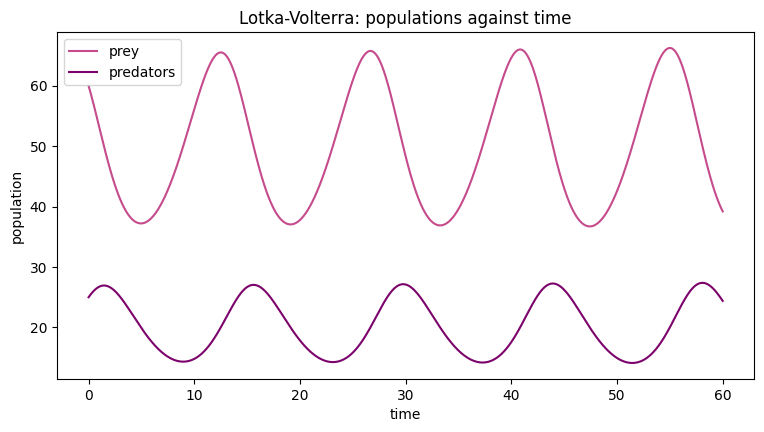

In [23]:
plt.figure(figsize=(9, 4.5))
plt.plot(t, x, label="prey", color="#C54B8C")
plt.plot(t, y, label="predators", color="#7C036B")
plt.xlabel("time"); plt.ylabel("population")
plt.title("Lotka-Volterra: populations against time")
plt.legend(); plt.show()

### Phase-Space Analysis

A phase-space representation provides an alternative way to visualize predator–prey dynamics.

Rather than plotting each population against time, the phase-space diagram plots predator abundance against prey abundance. Each point represents the state of the system at a particular time, and the resulting trajectory illustrates how the two populations evolve together.

The nonzero equilibrium occurs at 50 prey and 20 predators, where both population derivatives are zero.

For the ideal continuous Lotka–Volterra model, trajectories around this equilibrium form closed orbits, representing sustained population oscillations.

The numerical trajectory generated using Euler's method may deviate from these closed orbits because of accumulated integration error.

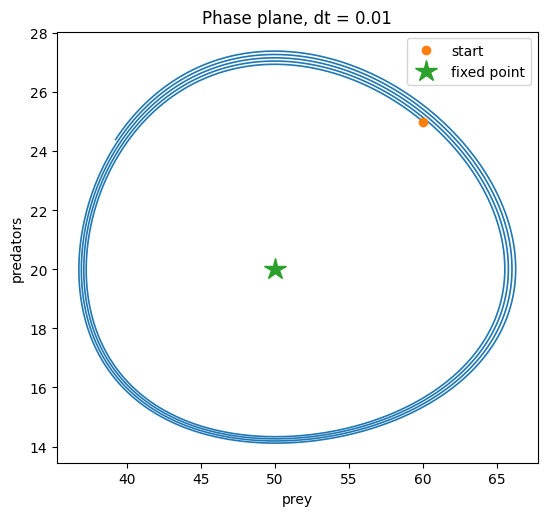

In [24]:
plt.figure(figsize=(6.2, 5.6))
plt.plot(x, y, linewidth=1.2)
plt.plot([x0], [y0], "o", label="start")
plt.plot([gamma/delta], [alpha/beta], "*", markersize=16, label="fixed point")
plt.xlabel("prey"); plt.ylabel("predators")
plt.title(f"Phase plane, dt = 0.01")
plt.legend(); plt.show()

### Numerical Drift in Euler Integration

Although the continuous Lotka–Volterra system produces closed trajectories, the numerical solution generated by forward Euler integration can exhibit outward spiraling.

To investigate this behavior, the model is simulated for 200 time units using a time step of `dt = 0.1`.

The resulting phase-space trajectory demonstrates how numerical error accumulates over repeated integration steps.

Instead of returning to the same population states after each oscillation, the numerical trajectory progressively moves away from its original orbit.

This behavior illustrates a limitation of forward Euler integration when applied to oscillatory dynamical systems.

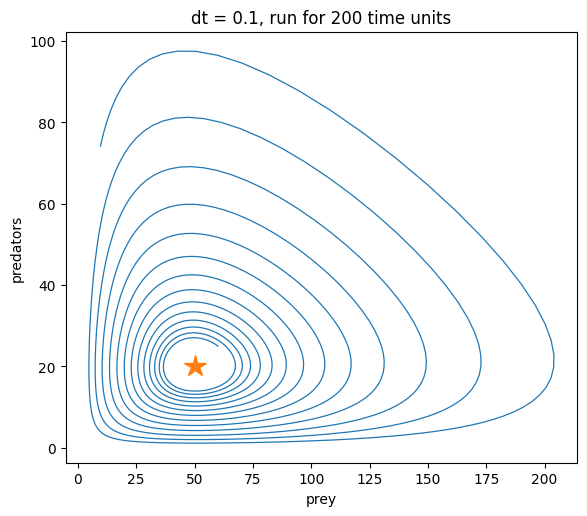

prey reaches: 204.0


In [25]:
t_long, x_long, y_long = run_lv(alpha, beta, gamma, delta, dt=0.1, T=200)

plt.figure(figsize=(6.6, 5.6))
plt.plot(x_long, y_long, linewidth=0.9)
plt.plot([gamma/delta], [alpha/beta], "*", markersize=16)
plt.xlabel("prey"); plt.ylabel("predators")
plt.title("dt = 0.1, run for 200 time units")
plt.show()

print("prey reaches:", round(x_long.max(), 1))

### Effect of Time-Step Size on Numerical Drift

Forward Euler integration approximates a continuous trajectory using discrete updates based on the derivatives at the beginning of each time step.

For oscillatory systems, these approximations can introduce systematic numerical drift, causing the simulated trajectory to deviate from the expected closed orbit.

To examine this effect, simulations are performed using time-step sizes of 0.1, 0.01, and 0.001 over the same 60-unit duration.

Comparing the resulting phase-space trajectories demonstrates how reducing the time-step size can decrease accumulated numerical error.

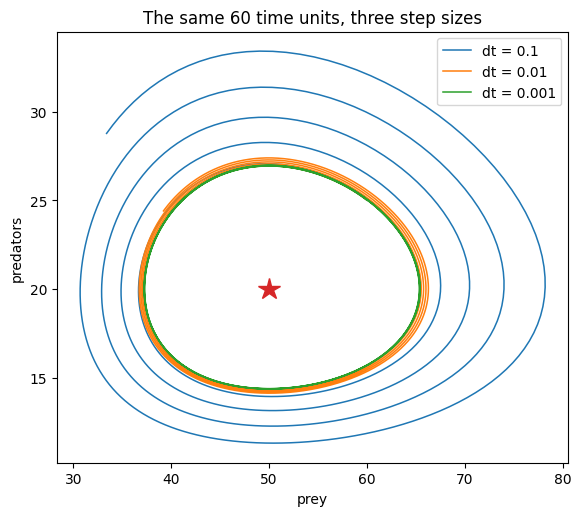

In [26]:
plt.figure(figsize=(6.6, 5.6))
for step in [0.1, 0.01, 0.001]:
    _, xs_, ys_ = run_lv(alpha, beta, gamma, delta, dt=step, T=60)
    plt.plot(xs_, ys_, linewidth=1.1, label=f"dt = {step}")
plt.plot([gamma/delta], [alpha/beta], "*", markersize=16)
plt.xlabel("prey"); plt.ylabel("predators")
plt.title("The same 60 time units, three step sizes")
plt.legend(); plt.show()

## Parameter Sensitivity Analysis

To investigate how model parameters influence predator–prey dynamics, each of the four Lotka–Volterra parameters is varied independently while the remaining parameters are held constant.

The baseline parameters are:

- Prey growth rate $(\alpha)$: 0.4
- Predation coefficient $(\beta)$: 0.02
- Predator mortality rate $(\gamma)$: 0.5
- Predator growth coefficient $(\delta)$: 0.01

For each parameter, values above and below the baseline are evaluated using a numerical time step of `dt = 0.001` over 60 time units.

Each simulation calculates the nonzero equilibrium population values and the minimum and maximum prey and predator populations.

This analysis examines how individual model parameters influence equilibrium locations and the range of population oscillations.

In [27]:
alpha = 0.4
beta  = 0.02
gamma = 0.5
delta = 0.01

def eval_param_change(param_name, alpha, beta, gamma, delta, dt=0.001, T=60.0):
  x = gamma/delta
  y = alpha/beta

  ts, xs, ys = run_lv(alpha, beta, gamma, delta, x0=60.0, y0=25.0, dt=dt, T=T)

  x_min, x_max = np.min(xs), np.max(xs)
  y_min, y_max = np.min(ys), np.max(ys)

  print(f"{param_name} | Equilibrium: prey={x:.1f}, predators={y:.1f}")

# baseline values
eval_param_change("Baseline", alpha, beta, gamma, delta)

# alpha (below: 0.2, above: 0.8)
eval_param_change("for alpha = 0.2:", 0.2, beta, gamma, delta)
eval_param_change("for alpha = 0.8:", 0.8, beta, gamma, delta)

# beta (below: 0.01, above: 0.04)
eval_param_change("for beta = 0.01:", alpha, 0.01, gamma, delta)
eval_param_change("for beta = 0.04:", alpha, 0.04, gamma, delta)

# gamma (below: 0.25, above: 1.0)
eval_param_change("for gamma = 0.25:", alpha, beta, 0.25, delta)
eval_param_change("for gamma = 1.0:", alpha, beta, 1.0, delta)

# delta (below: 0.005, above: 0.02)
eval_param_change("for delta = 0.005:", alpha, beta, gamma, 0.005)
eval_param_change("for delta = 0.02:", alpha, beta, gamma, 0.02)

Baseline | Equilibrium: prey=50.0, predators=20.0
for alpha = 0.2: | Equilibrium: prey=50.0, predators=10.0
for alpha = 0.8: | Equilibrium: prey=50.0, predators=40.0
for beta = 0.01: | Equilibrium: prey=50.0, predators=40.0
for beta = 0.04: | Equilibrium: prey=50.0, predators=10.0
for gamma = 0.25: | Equilibrium: prey=25.0, predators=20.0
for gamma = 1.0: | Equilibrium: prey=100.0, predators=20.0
for delta = 0.005: | Equilibrium: prey=100.0, predators=20.0
for delta = 0.02: | Equilibrium: prey=25.0, predators=20.0


### Results and Interpretation

The nonzero equilibrium of the Lotka–Volterra system is determined by:

$$
x^*=\frac{\gamma}{\delta}, \qquad y^*=\frac{\alpha}{\beta}
$$

Increasing the prey growth rate $\alpha$ or decreasing the predation coefficient $\beta$ increases the equilibrium predator population.

Conversely, increasing the predator mortality rate $\gamma$ or decreasing the predator growth coefficient $\delta$ increases the equilibrium prey population.

These relationships demonstrate that changes in one species' growth or mortality parameters can influence the equilibrium abundance of the interacting species.

For example, increasing the prey growth rate does not directly increase the equilibrium prey population. Instead, it allows the system to support a higher equilibrium predator population.

The simulations also demonstrate that parameter changes influence the minimum and maximum population values observed along the resulting trajectories.

### Quantifying Numerical Drift Using a Conserved Quantity

The classical Lotka–Volterra system possesses a conserved quantity that remains constant along exact trajectories of the continuous model.

For positive prey and predator populations, this quantity is defined as:

$$
V(x,y)=\delta x-\gamma\ln(x)+\beta y-\alpha\ln(y)
$$

Because $(V(x,y))$ remains constant along an exact trajectory, changes in its value during numerical simulation provide a way to quantify integration error.

To evaluate the accuracy of forward Euler integration, the model is simulated using time-step sizes of `dt = 0.001` and `dt = 0.1` over 60 time units.

For each simulation, the conserved quantity is evaluated at the beginning and end of the trajectory. Numerical drift is calculated as:

$$
\Delta V=V(x_{\mathrm{final}},y_{\mathrm{final}})-V(x_0,y_0)
$$

A value of $\Delta V$ closer to zero indicates better preservation of the conserved quantity over the simulated interval.

This experiment provides a quantitative measure of numerical drift and complements the earlier phase-space visualizations.

In [28]:
def V(x, y):
    return (delta*x) - (gamma*np.log(x)) + (beta*y) - (alpha*np.log(y))

#dt = 0.001
ts, xs, ys = run_lv(alpha, beta, gamma, delta, x0=60.0, y0=25.0, dt=0.001, T=60)

V_start = V(xs[0], ys[0])
V_end = V(xs[-1], ys[-1])

print(f"For dt=0.001:\nV at start: {V_start}, V at end: {V_end}")

#dt = 0.1
ts, xs, ys = run_lv(alpha, beta, gamma, delta, x0=60.0, y0=25.0, dt=0.1, T=60)

V_start = V(xs[0], ys[0])
V_end = V(xs[-1], ys[-1])

print(f"For dt=0.1:\nV at start: {V_start}, V at end: {V_end}")


dts = [0.2, 0.1, 0.05, 0.01, 0.005]

drifts = []

for dt in dts:
  ts, xs, ys = run_lv(alpha, beta, gamma, delta, x0=60.0, y0=25.0, dt=dt, T=200)

  V_start = V(xs[0], ys[0])
  V_end = V(xs[-1], ys[-1])

  drift = V_end - V_start
  drifts.append(drift)

  print(f"dt: {dt}: Drift: {drift}")

for i in range(len(drifts)-1):
  ratio = drifts[i]/drifts[i+1]
  print(f"Ratio between dt = {dts[i]} and dt = {dts[i+1]}: {ratio}")

For dt=0.001:
V at start: -2.2347226110583307, V at end: -2.2344849642801865
For dt=0.1:
V at start: -2.2347226110583307, V at end: -2.18862004614149
dt: 0.2: Drift: 9.339035227805528
dt: 0.1: Drift: 0.9571312081811612
dt: 0.05: Drift: 0.12075849279415074
dt: 0.01: Drift: 0.00959996212581915
dt: 0.005: Drift: 0.004325139182017157
Ratio between dt = 0.2 and dt = 0.1: 9.757319736290409
Ratio between dt = 0.1 and dt = 0.05: 7.925994984160007
Ratio between dt = 0.05 and dt = 0.01: 12.579059293303889
Ratio between dt = 0.01 and dt = 0.005: 2.219572994490763


### Results and Interpretation

The numerical simulations demonstrate that forward Euler integration introduces systematic drift in the conserved quantity of the Lotka–Volterra system.

Across the tested time-step sizes, the calculated drift is positive, indicating that the numerical trajectories move toward higher values of $V(x,y)$ rather than remaining on their original conserved contours.

This behavior is consistent with the outward spiraling observed in the phase-space simulations. Because the exact system follows closed trajectories, the outward spiral represents numerical error rather than a property of the underlying biological model.

Reducing the time-step size decreases the accumulated drift, demonstrating that smaller Euler steps improve preservation of the conserved quantity.

However, smaller time steps also require more numerical iterations, creating a tradeoff between computational accuracy and efficiency.

### Comparing Euler and Midpoint Numerical Integration

Forward Euler integration is a first-order numerical method that estimates the next system state using derivatives evaluated at the beginning of each time step.

Although straightforward to implement, Euler's method can accumulate substantial numerical error when simulating oscillatory dynamical systems.

To improve numerical accuracy, the explicit midpoint method is implemented as a second-order alternative.

The midpoint method consists of four operations:

1. Calculate the population derivatives at the current state.
2. Estimate the population state halfway through the time step.
3. Recalculate the derivatives at the estimated midpoint.
4. Update the original population state using the midpoint derivatives over the full time step.

The functions `midpoint_step()` and `run_midpoint()` implement this approach for the Lotka–Volterra system.

Both numerical methods are evaluated over 200 time units using `dt = 0.1`.

Their accuracy is compared by calculating drift in the conserved quantity $V(x,y)$ and examining their phase-space trajectories.

Euler drift: 0.9571312081811612
Midpoint drift: 3.490587844279247e-05


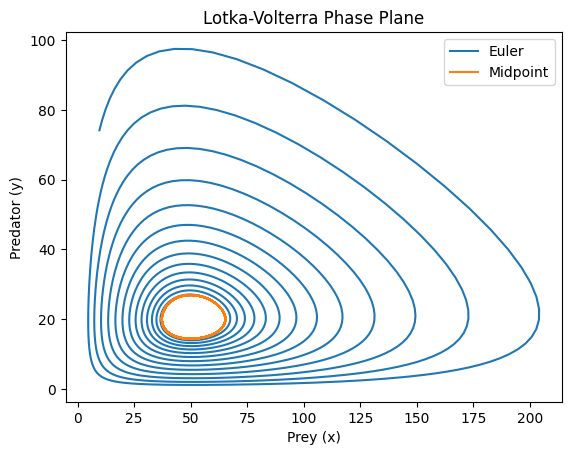

In [29]:
def midpoint_step(x, y, alpha, beta, gamma, delta, dt):
    dx1 = (alpha*x) - (beta*x*y)
    dy1 = (delta*x*y) - (gamma*y)

    x_mid = x + dx1 * (dt/2)
    y_mid = y + dy1 * (dt/2)

    dx2 = (alpha*x_mid) - (beta*x_mid*y_mid)
    dy2 = (delta*x_mid*y_mid) - (gamma*y_mid)

    x_new = x + dx2 * dt
    y_new = y + dy2 * dt

    return x_new, y_new

def run_midpoint(alpha, beta, gamma, delta, x0=60.0, y0=25.0, dt=0.01, T=60.0):
    x, y = x0, y0

    ts, xs, ys = [0.0], [x], [y]

    for k in range(int(T / dt)):
        x, y = midpoint_step(x, y, alpha, beta, gamma, delta, dt)
        ts.append((k + 1) * dt)
        xs.append(x)
        ys.append(y)

    return np.array(ts), np.array(xs), np.array(ys)


ts_e, xs_e, ys_e = run_lv(alpha, beta, gamma, delta, dt=0.1, T=200)

V_start_e = V(xs_e[0], ys_e[0])
V_end_e = V(xs_e[-1], ys_e[-1])
drift_e = V_end_e - V_start_e

ts_m, xs_m, ys_m = run_midpoint(alpha, beta, gamma, delta, dt=0.1, T=200)

V_start_m = V(xs_m[0], ys_m[0])
V_end_m = V(xs_m[-1], ys_m[-1])
drift_m = V_end_m - V_start_m

print(f"Euler drift: {drift_e}")
print(f"Midpoint drift: {drift_m}")

import matplotlib.pyplot as plt

plt.plot(xs_e, ys_e, label="Euler")
plt.plot(xs_m, ys_m, label="Midpoint")

plt.xlabel("Prey (x)")
plt.ylabel("Predator (y)")
plt.title("Lotka-Volterra Phase Plane")
plt.legend()
plt.show()

### Results and Interpretation

The explicit midpoint method substantially improves preservation of the conserved quantity compared with forward Euler integration.

At a time step of `dt = 0.1`, midpoint integration produces an absolute drift of approximately 0.000035. In comparison, Euler integration produces a drift of approximately 0.004325 even when using the much smaller time step of `dt = 0.005`.

| Integration Method | Time Step | Absolute Drift |
|---|---:|---:|
| Forward Euler | 0.005 | 0.004325 |
| Explicit midpoint | 0.1 | 0.000035 |

The midpoint method therefore produces approximately 124 times less drift despite using a time step 20 times larger.

Although midpoint integration requires two derivative evaluations per step instead of one, its higher-order accuracy allows it to achieve better numerical conservation with substantially fewer integration steps.

The phase-space comparison at `dt = 0.1` further illustrates the difference between the methods. Euler integration exhibits outward numerical drift, while midpoint integration more closely preserves the closed trajectories expected from the continuous Lotka–Volterra system.

These findings demonstrate that selecting a higher-order numerical integration method can improve computational accuracy more efficiently than simply reducing the time-step size.

## Logistic Prey Growth and Carrying Capacity

The classical Lotka–Volterra model assumes that prey populations grow exponentially in the absence of predators. This assumption does not account for environmental limitations such as finite food availability, habitat space, or competition for resources.

To introduce density-dependent prey growth, the model is extended using a logistic growth term.

The modified system is represented by:

$$
\frac{dx}{dt}=\alpha x\left(1-\frac{x}{K}\right)-\beta xy
$$

$$
\frac{dy}{dt}=\delta xy-\gamma y
$$

Here, $K$ represents the carrying capacity of the prey population.

As prey abundance approaches the carrying capacity, its intrinsic growth rate decreases, limiting population expansion.

The extended model is implemented using the explicit midpoint integration method to reduce numerical error.

Simulations are conducted with carrying capacities of $(K=500)$, $(K=200)$, and $(K=100)$, using a time step of `dt = 0.01` over 400 time units.

These experiments investigate how environmental resource limitations influence predator–prey oscillations and long-term population behavior.

K = 500
Final prey = 50.00
Final predator = 18.00



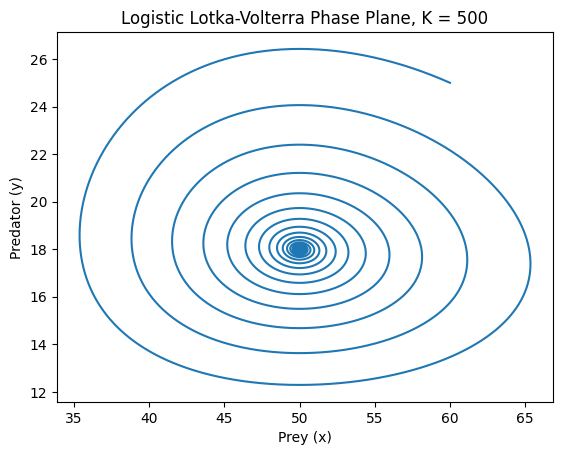

K = 200
Final prey = 50.00
Final predator = 15.00



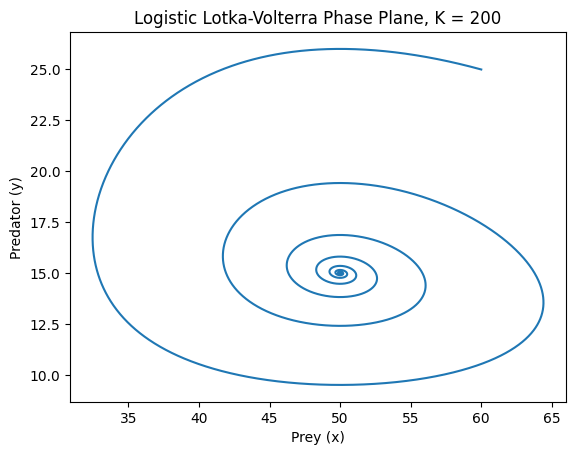

K = 100
Final prey = 50.00
Final predator = 10.00



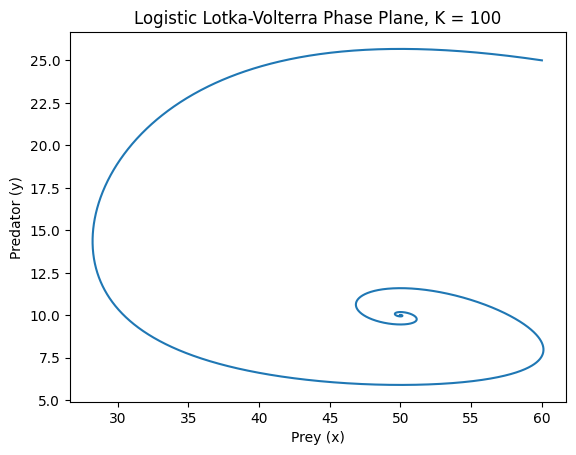

In [30]:
def lv_logistic_step(x, y, alpha, beta, gamma, delta, K, dt):
    dx1 = (alpha*x*(1 - x/K)) - (beta*x*y)
    dy1 = (delta*x*y) - (gamma*y)

    x_mid = x + dx1 * (dt/2)
    y_mid = y + dy1 * (dt/2)

    dx2 = (alpha*x_mid*(1 - x_mid/K)) - (beta*x_mid*y_mid)
    dy2 = (delta*x_mid*y_mid) - (gamma*y_mid)

    x_new = x + dx2 * dt
    y_new = y + dy2 * dt

    return x_new, y_new

def run_lv_logistic(alpha, beta, gamma, delta, K, x0=60.0, y0=25.0, dt=0.01, T=60.0):
    x, y = x0, y0

    ts, xs, ys = [0.0], [x], [y]

    for k in range(int(T / dt)):
        x, y = lv_logistic_step(
            x, y, alpha, beta, gamma, delta, K, dt)
        ts.append((k + 1) * dt)
        xs.append(x)
        ys.append(y)

    return np.array(ts), np.array(xs), np.array(ys)


import matplotlib.pyplot as plt

for K in [500, 200, 100]:

    ts, xs, ys = run_lv_logistic(alpha, beta, gamma, delta, K=K, x0=60.0, y0=25.0, dt=0.01, T=400.0)

    print(f"K = {K}")
    print(f"Final prey = {xs[-1]:.2f}")
    print(f"Final predator = {ys[-1]:.2f}")
    print()

    plt.figure()
    plt.plot(xs, ys)
    plt.xlabel("Prey (x)")
    plt.ylabel("Predator (y)")
    plt.title(f"Logistic Lotka-Volterra Phase Plane, K = {K}")
    plt.show()

### Results and Interpretation

Introducing logistic prey growth changes the long-term behavior of the predator–prey system.

Unlike the classical Lotka–Volterra model, which exhibits sustained oscillations around its nonzero equilibrium, the logistic extension introduces density-dependent regulation of prey growth.

Across the tested carrying capacities, the phase-space trajectories approach stable coexistence equilibria rather than maintaining closed orbits.

The carrying capacity influences the equilibrium predator population because greater resource availability allows the environment to support more prey growth and, consequently, a larger predator population.

These results demonstrate how incorporating ecological constraints can change the qualitative behavior of a mathematical model, producing damped oscillations and eventual stabilization.

The logistic extension therefore provides a more biologically realistic representation of resource-limited predator–prey interactions, while remaining a simplified description of real ecosystems.